In [1]:
import numpy as np, pandas as pd, joblib
from pathlib import Path
from sklearn.model_selection import train_test_split

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
proc = root / "data" / "processed"
clean = pd.read_parquet(proc / "clean.parquet")

const = [c for c in clean.select_dtypes(include=np.number).columns if clean[c].nunique() <= 1]
X = clean.drop(columns=["Label", "source_file"] + const)
y_multi = clean["Label"]
y_bin = (y_multi != "BENIGN").astype(int)
print("Features :", X.shape[1], "| Lignes :", len(X))

# 60 % train / 20 % val / 20 % test, stratifié sur les classes
X_tr, X_tmp, yb_tr, yb_tmp, ym_tr, ym_tmp = train_test_split(
    X, y_bin, y_multi, test_size=0.4, stratify=y_multi, random_state=42)
X_val, X_te, yb_val, yb_te, ym_val, ym_te = train_test_split(
    X_tmp, yb_tmp, ym_tmp, test_size=0.5, stratify=ym_tmp, random_state=42)

for name, Xs, ys in [("train", X_tr, ym_tr), ("val", X_val, ym_val), ("test", X_te, ym_te)]:
    Xs.assign(Label=ys).to_parquet(proc / f"{name}.parquet")
    print(name, Xs.shape)

Features : 70 | Lignes : 2498185
train (1498911, 70)
val (499637, 70)
test (499637, 70)


In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix

clf = DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=42)
clf.fit(X_tr, yb_tr)

def metrics(model, X, y):
    tn, fp, fn, tp = confusion_matrix(y, model.predict(X)).ravel()
    return {"precision": tp/(tp+fp), "recall": tp/(tp+fn),
            "f1": 2*tp/(2*tp+fp+fn), "FPR": fp/(fp+tn)}

print("VALIDATION :", {k: round(v, 4) for k, v in metrics(clf, X_val, yb_val).items()})
joblib.dump(clf, root / "models" / "baseline_tree.joblib")

VALIDATION : {'precision': np.float64(0.9914), 'recall': np.float64(0.9972), 'f1': np.float64(0.9943), 'FPR': np.float64(0.0018)}


['C:\\Users\\Ultrapc\\Desktop\\pfe-soc-ml\\models\\baseline_tree.joblib']

In [3]:
import time
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, max_depth=20,
                        class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1,
                        tree_method="hist", n_jobs=-1, random_state=42),
}

rows = []
for name, m in models.items():
    t0 = time.time(); m.fit(X_tr, yb_tr); t_fit = time.time() - t0
    t0 = time.time(); m.predict(X_val.iloc[:10000]); t_inf = (time.time() - t0) / 10000 * 1000
    r = metrics(m, X_val, yb_val)
    rows.append({"modele": name, **{k: round(v, 4) for k, v in r.items()},
                 "train_s": round(t_fit), "inference_ms_par_flux": round(t_inf, 4)})
    joblib.dump(m, root / "models" / f"{name}.joblib")

base = metrics(clf, X_val, yb_val)
rows.insert(0, {"modele": "DecisionTree (baseline)", **{k: round(v, 4) for k, v in base.items()}})
print(pd.DataFrame(rows))

                    modele  precision  recall      f1     FPR  train_s  \
0  DecisionTree (baseline)     0.9914  0.9972  0.9943  0.0018      NaN   
1             RandomForest     0.9951  0.9989  0.9970  0.0010    140.0   
2                  XGBoost     0.9969  0.9987  0.9978  0.0006     20.0   

   inference_ms_par_flux  
0                    NaN  
1                 0.0045  
2                 0.0020  


In [4]:
xgb = models["XGBoost"]
pred = xgb.predict(X_val)
res = pd.DataFrame({"label": ym_val.values, "pred": pred})

# Recall par type d'attaque
att = res[res["label"] != "BENIGN"].groupby("label")["pred"].agg(n="count", detectees="sum")
att["recall_%"] = (att["detectees"] / att["n"] * 100).round(2)
print(att.sort_values("recall_%"))

# Fausses alertes et attaques ratées
fp = ((res["label"] == "BENIGN") & (res["pred"] == 1)).sum()
fn = ((res["label"] != "BENIGN") & (res["pred"] == 0)).sum()
print("Faux positifs :", fp, "| Faux négatifs :", fn)

                              n  detectees  recall_%
label                                               
Heartbleed                    2          1     50.00
Infiltration                  7          5     71.43
Bot                         389        302     77.63
Web Attack Brute Force      294        291     98.98
Web Attack XSS              131        130     99.24
DoS Slowhttptest           1045       1044     99.90
DoS slowloris              1077       1076     99.91
DoS GoldenEye              2058       2057     99.95
DDoS                      25603      25599     99.98
DoS Hulk                  34569      34561     99.98
PortScan                  18139      18137     99.99
FTP-Patator                1186       1186    100.00
SSH-Patator                 644        644    100.00
Web Attack Sql Injection      4          4    100.00
Faux positifs : 263 | Faux négatifs : 111


In [5]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=100, contamination=0.01, n_jobs=-1, random_state=42)
iso.fit(X_tr[yb_tr == 0].sample(300_000, random_state=42))

pred_iso = (iso.predict(X_val) == -1).astype(int)   # -1 = anomalie
tn, fp_i, fn_i, tp = confusion_matrix(yb_val, pred_iso).ravel()
print({"precision": round(tp/(tp+fp_i), 4), "recall": round(tp/(tp+fn_i), 4),
       "f1": round(2*tp/(2*tp+fp_i+fn_i), 4), "FPR": round(fp_i/(fp_i+tn), 4)})

{'precision': np.float64(0.6108), 'recall': np.float64(0.0763), 'f1': np.float64(0.1357), 'FPR': np.float64(0.01)}


In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score

idx = X_val.sample(100_000, random_state=42).index
score = -iso.score_samples(X_val.loc[idx])       # plus élevé = plus anormal
y_s = yb_val.loc[idx]
print("ROC-AUC :", round(roc_auc_score(y_s, score), 4))
print("PR-AUC  :", round(average_precision_score(y_s, score), 4))

ROC-AUC : 0.813
PR-AUC  : 0.5198


In [7]:
bot = X_val[ym_val.values == "Bot"].copy()
bot["pred"] = pred[ym_val.values == "Bot"]
benign = X_val[ym_val.values == "BENIGN"]

cols = ["Flow Duration", "Total Fwd Packets", "Flow Packets/s", "Destination Port",
        "Fwd Packet Length Mean", "Init_Win_bytes_forward"]
cmp = pd.DataFrame({
    "Bot detectes": bot[bot.pred == 1][cols].median(),
    "Bot rates": bot[bot.pred == 0][cols].median(),
    "BENIGN": benign[cols].median()})
print(cmp)

                        Bot detectes     Bot rates        BENIGN
Flow Duration            61066.50000  1.003334e+06  46420.000000
Total Fwd Packets            3.00000  3.000000e+00      2.000000
Flow Packets/s             325.75827  5.980062e+00     84.423805
Destination Port          8080.00000  8.080000e+03     80.000000
Fwd Packet Length Mean       6.00000  0.000000e+00     38.000000
Init_Win_bytes_forward    8192.00000  8.192000e+03    123.000000


In [8]:
proba = xgb.predict_proba(X_val)[:, 1]

rows = []
for t in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]:
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb_val, p).ravel()
    rows.append({"seuil": t, "precision": round(tp/(tp+fp), 4), "recall": round(tp/(tp+fn), 4),
                 "FPR": round(fp/(fp+tn), 5), "FP": fp, "FN": fn})
print(pd.DataFrame(rows))

   seuil  precision  recall      FPR   FP    FN
0   0.05     0.9934  0.9999  0.00136  562     8
1   0.10     0.9944  0.9999  0.00116  482    11
2   0.20     0.9950  0.9997  0.00103  426    24
3   0.30     0.9955  0.9995  0.00093  385    43
4   0.50     0.9969  0.9987  0.00063  263   111
5   0.70     0.9973  0.9980  0.00056  231   170
6   0.90     0.9979  0.9952  0.00042  176   405
7   0.95     0.9984  0.9852  0.00033  136  1256
8   0.99     0.9997  0.9181  0.00005   21  6977


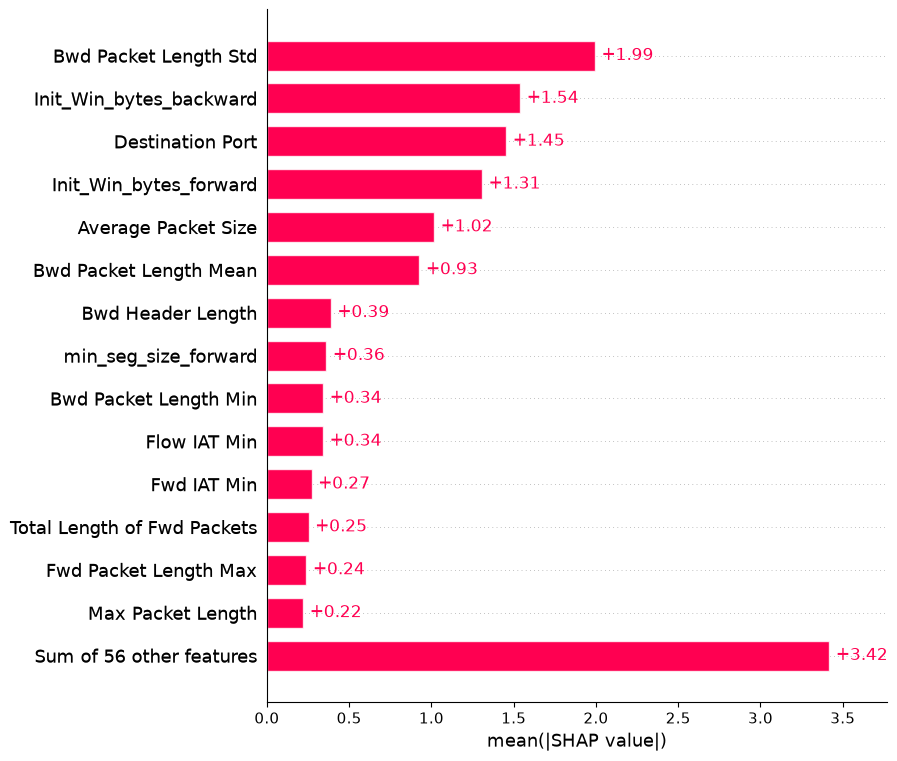

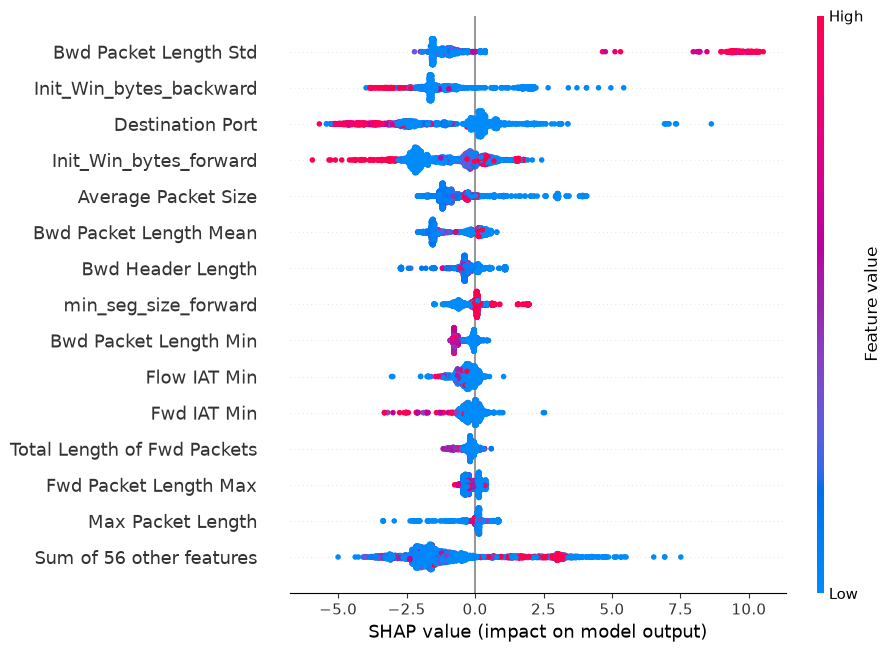

In [9]:
import shap
import matplotlib.pyplot as plt

sample = X_val.sample(2000, random_state=42)
explainer = shap.TreeExplainer(xgb)
sv = explainer(sample)

shap.plots.bar(sv, max_display=15)
shap.plots.beeswarm(sv, max_display=15)

In [10]:
proba = xgb.predict_proba(X_val)[:, 1]
score = (proba * 100).round(1)

bins = [0, 10, 30, 90, 100.01]
labels = ["Faible", "Moyen", "Élevé", "Critique"]
niveau = pd.cut(score, bins=bins, labels=labels, right=False)

res = pd.DataFrame({"niveau": niveau, "attaque": yb_val.values})
tab = res.groupby("niveau", observed=True)["attaque"].agg(flux="count", attaques="sum")
tab["part_attaques_%"] = (tab["attaques"] / tab["flux"] * 100).round(2)
print(tab)

            flux  attaques  part_attaques_%
niveau                                     
Faible    414018        11             0.00
Moyen        129        32            24.81
Élevé        570       361            63.33
Critique   84920     84744            99.79


In [11]:
res = pd.DataFrame({"niveau": niveau, "label": ym_val.values})
print(pd.crosstab(res["label"], res["niveau"]))

niveau                    Faible  Moyen  Élevé  Critique
label                                                   
BENIGN                    414007     97    209       176
Bot                            4     26     97       262
DDoS                           0      3     16     25584
DoS GoldenEye                  0      0      5      2053
DoS Hulk                       1      0    138     34430
DoS Slowhttptest               1      0      6      1038
DoS slowloris                  0      0      3      1074
FTP-Patator                    0      0      6      1180
Heartbleed                     1      0      0         1
Infiltration                   2      0      1         4
PortScan                       2      0     79     18058
SSH-Patator                    0      0      1       643
Web Attack Brute Force         0      2      2       290
Web Attack Sql Injection       0      0      2         2
Web Attack XSS                 0      1      5       125


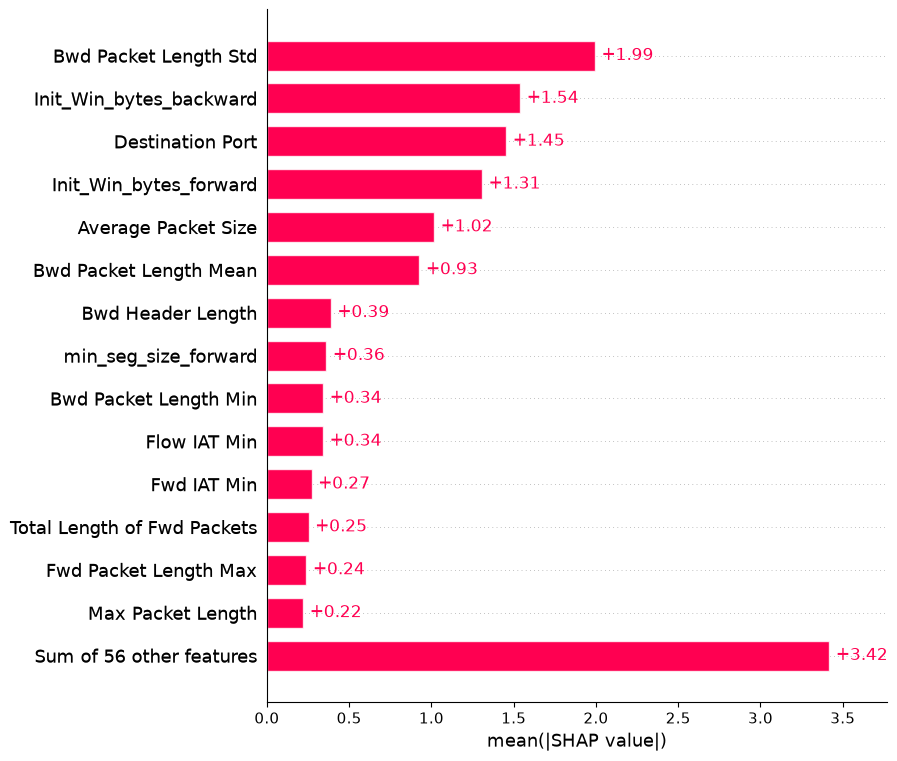

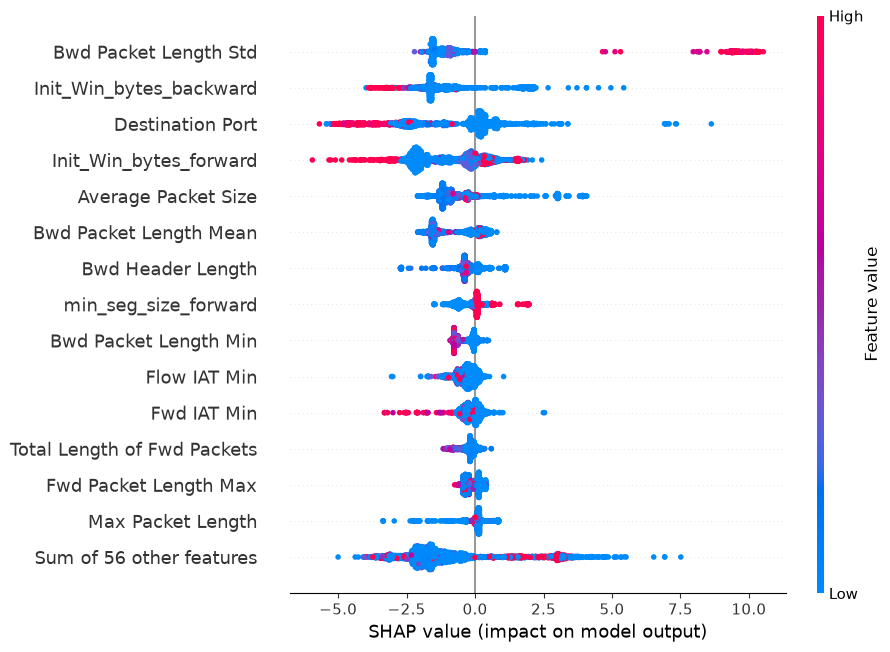

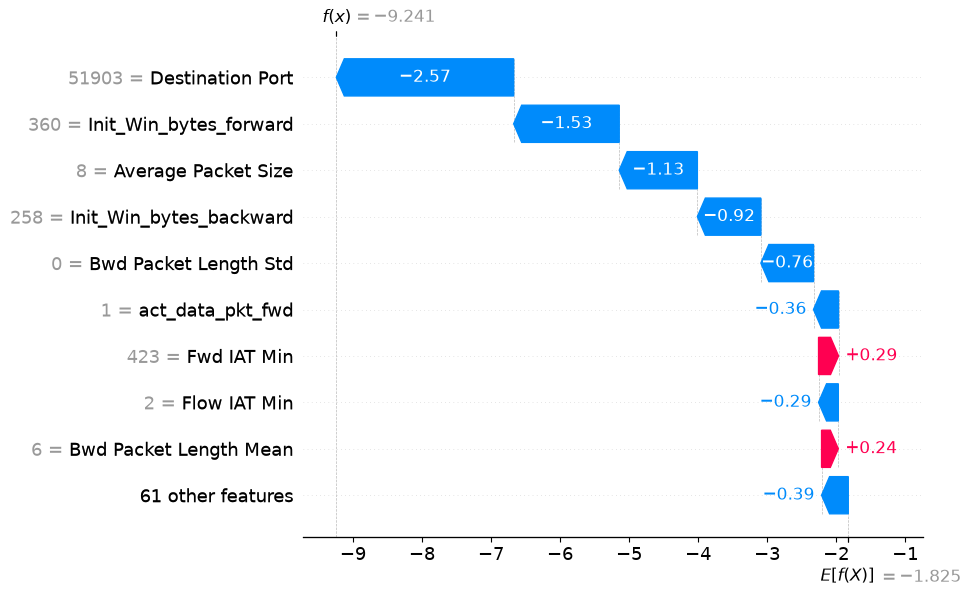

In [12]:
import shap

sample = X_val.sample(2000, random_state=42)
explainer = shap.TreeExplainer(xgb)
sv = explainer(sample)

shap.plots.bar(sv, max_display=15)
shap.plots.beeswarm(sv, max_display=15)
shap.plots.waterfall(sv[0])        # explication d'un seul flux

In [13]:
drop = ["Destination Port", "Init_Win_bytes_forward", "Init_Win_bytes_backward"]

xgb2 = XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1,
                     tree_method="hist", n_jobs=-1, random_state=42)
xgb2.fit(X_tr.drop(columns=drop), yb_tr)

Xv2 = X_val.drop(columns=drop)
print("Sans raccourcis :", {k: round(v, 4) for k, v in metrics(xgb2, Xv2, yb_val).items()})

pred2 = xgb2.predict(Xv2)
res2 = pd.DataFrame({"label": ym_val.values, "pred": pred2})
att2 = res2[res2["label"] != "BENIGN"].groupby("label")["pred"].agg(n="count", detectees="sum")
att2["recall_%"] = (att2["detectees"] / att2["n"] * 100).round(2)
print(att2.sort_values("recall_%"))

Sans raccourcis : {'precision': np.float64(0.9955), 'recall': np.float64(0.9923), 'f1': np.float64(0.9939), 'FPR': np.float64(0.0009)}
                              n  detectees  recall_%
label                                               
Web Attack Sql Injection      4          1     25.00
Bot                         389        151     38.82
Heartbleed                    2          1     50.00
Infiltration                  7          4     57.14
Web Attack Brute Force      294        269     91.50
SSH-Patator                 644        594     92.24
Web Attack XSS              131        123     93.89
DoS Hulk                  34569      34287     99.18
FTP-Patator                1186       1178     99.33
DoS Slowhttptest           1045       1041     99.62
DoS slowloris              1077       1075     99.81
DDoS                      25603      25578     99.90
DoS GoldenEye              2058       2057     99.95
PortScan                  18139      18137     99.99


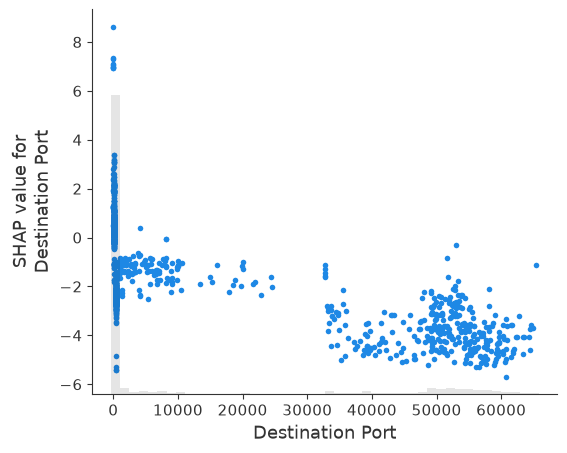

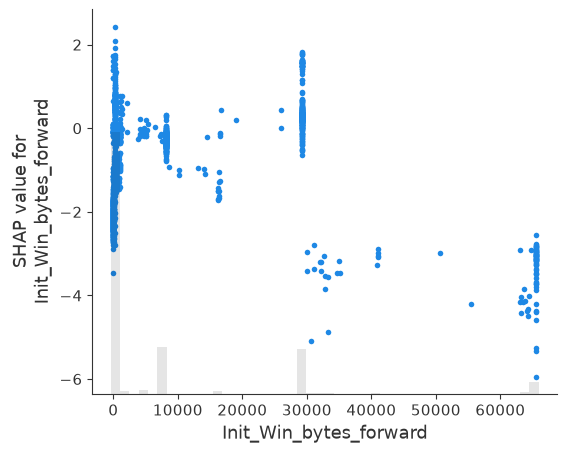

In [14]:
shap.plots.scatter(sv[:, "Destination Port"])
shap.plots.scatter(sv[:, "Init_Win_bytes_forward"])

In [ ]:
y_all = (clean["Label"] != "BENIGN").astype(int)
cols_all = list(X.columns)
cols_rob = [c for c in cols_all if c not in drop]

rows = []
for held in sorted(clean["source_file"].unique()):
    if held.startswith("Monday"):          # uniquement du trafic normal
        continue
    te = (clean["source_file"] == held).to_numpy()
    for name, cols in [("complet", cols_all), ("robuste", cols_rob)]:
        m = XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1,
                          tree_method="hist", n_jobs=-1, random_state=42)
        m.fit(clean.loc[~te, cols], y_all[~te])
        p = m.predict(clean.loc[te, cols])
        yt = y_all[te].to_numpy()
        rows.append({"fichier_test": held[:32], "modele": name,
                     "attaques": int(yt.sum()),
                     "recall": round(((p == 1) & (yt == 1)).sum() / yt.sum(), 4),
                     "FPR": round(((p == 1) & (yt == 0)).sum() / (yt == 0).sum(), 4)})
print(pd.DataFrame(rows))

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)
rows = []
for held in sorted(clean["source_file"].unique()):
    if held.startswith("Monday"):
        continue
    te = (clean["source_file"] == held).to_numpy()
    benign_tr = clean.loc[(~te) & (y_all.to_numpy() == 0), cols_rob].sample(300_000, random_state=42)
    iso = IsolationForest(n_estimators=100, n_jobs=-1, random_state=42).fit(benign_tr)

    pos = np.where(te)[0]
    if len(pos) > 100_000:
        pos = rng.choice(pos, 100_000, replace=False)
    Xt, yt = clean.iloc[pos][cols_rob], y_all.iloc[pos].to_numpy()
    if yt.sum() == 0:
        continue
    rows.append({"fichier_test": held[:32], "attaques": int(yt.sum()),
                 "AUC_isoforest": round(roc_auc_score(yt, -iso.score_samples(Xt)), 4)})
print(pd.DataFrame(rows))

In [ ]:
from sklearn.metrics import roc_curve

rows = []
for held in sorted(clean["source_file"].unique()):
    if held.startswith("Monday"):
        continue
    te = (clean["source_file"] == held).to_numpy()
    benign_tr = clean.loc[(~te) & (y_all.to_numpy() == 0), cols_rob].sample(300_000, random_state=42)
    iso = IsolationForest(n_estimators=100, n_jobs=-1, random_state=42).fit(benign_tr)

    pos = np.where(te)[0]
    if len(pos) > 100_000:
        pos = rng.choice(pos, 100_000, replace=False)
    yt = y_all.iloc[pos].to_numpy()
    if yt.sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(yt, -iso.score_samples(clean.iloc[pos][cols_rob]))
    rows.append({"fichier_test": held[:32],
                 "recall@FPR1%": round(float(np.interp(0.01, fpr, tpr)), 4),
                 "recall@FPR5%": round(float(np.interp(0.05, fpr, tpr)), 4)})
print(pd.DataFrame(rows))

In [ ]:
proba2 = xgb2.predict_proba(Xv2)[:, 1]

rows = []
for t in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.95]:
    p = (proba2 >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb_val, p).ravel()
    rows.append({"seuil": t, "precision": round(tp/(tp+fp), 4), "recall": round(tp/(tp+fn), 4),
                 "FPR": round(fp/(fp+tn), 5), "FP": fp, "FN": fn})
print(pd.DataFrame(rows))

score2 = (proba2 * 100).round(1)
niveau2 = pd.cut(score2, bins=[0, 10, 30, 90, 100.01],
                 labels=["Faible", "Moyen", "Élevé", "Critique"], right=False)
res2 = pd.DataFrame({"niveau": niveau2, "attaque": yb_val.values})
tab2 = res2.groupby("niveau", observed=True)["attaque"].agg(flux="count", attaques="sum")
tab2["part_attaques_%"] = (tab2["attaques"] / tab2["flux"] * 100).round(2)
print(tab2)

In [ ]:
res2 = pd.DataFrame({"niveau": niveau2, "label": ym_val.values})
print(pd.crosstab(res2["label"], res2["niveau"]))

In [ ]:
import json
xgb2.save_model(root / "models" / "xgb_robuste.json")
xgb.save_model(root / "models" / "xgb_complet.json")

config = {"features_robuste": list(Xv2.columns),
          "features_complet": list(X_val.columns),
          "bornes_niveaux": [10, 30, 90],
          "niveaux": ["Faible", "Moyen", "Élevé", "Critique"],
          "seuil_decision": 0.5}
(root / "models" / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

In [ ]:
import sys
import numpy as np, pandas as pd
from pathlib import Path

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(root))
from src.scoring import load_model, score_flows

val = pd.read_parquet(root / "data" / "processed" / "val.parquet")
y_bin = (val["Label"] != "BENIGN").astype(int)

m = load_model("robuste")
out = score_flows(val, m, "robuste")
print(out.head())

res = pd.DataFrame({"niveau": out["niveau"], "attaque": y_bin.values})
tab = res.groupby("niveau", observed=True)["attaque"].agg(flux="count", attaques="sum")
tab["part_attaques_%"] = (tab["attaques"] / tab["flux"] * 100).round(2)
print(tab.reindex(["Faible", "Moyen", "Élevé", "Critique"]))